# CitizenTech "Cidade Para Todos": o que a computação quântica poderia mudar

**FIAP · Global Solution 2026.2 · Computação Quântica · Turma 2TIAPF**

Integrantes: Octavio Augusto Ramalho Brandão Pires (RM 555696)

---

Este notebook acompanha o relatório em PDF da entrega. Ele serve para mostrar, com experimentos pequenos, duas coisas:

1. **Onde a busca clássica do nosso assistente começa a pesar** quando a base de documentos cresce de 11 manuais para o volume de uma cidade como São Paulo.
2. **O que um algoritmo quântico de busca faria nesse mesmo problema**, simulado em um computador comum, e quais são os limites dele hoje.

O enunciado diz que não é preciso programar um algoritmo quântico e que o foco está no raciocínio. Por isso o código aqui é uma ferramenta para entender o argumento. Não é uma prova de que o quântico já seja melhor.

**Combinado de honestidade do grupo.** Tudo o que roda neste notebook é simulação clássica de circuitos quânticos pequenos. Simular qubits em CPU custa mais tempo, não menos. O que a simulação permite observar é o comportamento do algoritmo: quantas iterações ele pede, qual a probabilidade de acerto e como o ruído atrapalha. Qualquer afirmação sobre ganho de velocidade em hardware real é uma projeção e está marcada como tal.

**Capacidade quântica escolhida:** busca em grandes bases (Grover e swap test, de forma híbrida). A criptografia pós-quântica (PQC) aparece na Parte 4 como medida complementar de segurança no curto prazo, não como a capacidade principal.

| Parte | O que fazemos |
|---|---|
| 1 | Medimos os limites da busca clássica (tempo, memória, recall e segurança) |
| 2 | Simulamos o algoritmo de Grover em escala pequena, com e sem ruído |
| 3 | Simulamos a comparação de similaridade por *swap test*, que seria a base de um re-ranqueamento quântico |
| 4 | Discutimos a QRAM e a criptografia pós-quântica (PQC), que decidem se isso é viável |
| 5 | Resumimos o roadmap e as conclusões |

In [1]:
# Instala o que faltar (no Colab quase tudo já vem instalado, o qiskit costuma faltar)
import importlib.util, subprocess, sys, os, time, math

def garantir(pacote, modulo=None):
    if importlib.util.find_spec(modulo or pacote) is None:
        print("Instalando", pacote)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote])

for pacote, modulo in [("numpy", None), ("matplotlib", None), ("pandas", None),
                       ("scikit-learn", "sklearn"), ("qiskit", None)]:
    garantir(pacote, modulo)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)       # as figuras também são usadas no relatório
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
SEED = 42                                # semente fixa para os resultados serem repetíveis
rng = np.random.default_rng(SEED)
print("Pronto. numpy", np.__version__)

Instalando qiskit
Pronto. numpy 2.4.6


# Parte 1. Onde a IA clássica do protótipo fica lenta, cara, imprecisa ou insegura

## 1.0 O ponto de partida

O protótipo do CitizenTech (entrega de IA Generativa) é um assistente RAG com este desenho:

- 11 documentos sobre serviços públicos, que viram cerca de 42 trechos (*chunks*);
- embeddings de 384 dimensões (`paraphrase-multilingual-MiniLM-L12-v2`);
- índice FAISS `IndexFlatIP`, que faz **busca exata** por produto interno (cosseno), combinado com BM25 e fusão RRF;
- recuperação dos 3 melhores trechos (k = 3).

Com 42 trechos, comparar a pergunta com todos eles é instantâneo. A pergunta deste trabalho é outra: **o que acontece se a base deixar de ser um piloto?** Pensamos em cenários como milhões de protocolos de ouvidoria, atualizações de legislação e cadastros. Esses números são hipóteses do grupo, não dados medidos.

## 1.1 Tempo e memória da busca exata

No experimento abaixo geramos vetores aleatórios de 384 dimensões e medimos quanto tempo uma única consulta leva para ser comparada com todos eles. Vetores aleatórios servem bem para medir custo computacional, mas não dizem nada sobre qualidade de resposta.

In [2]:
D = 384                                           # dimensão dos embeddings do protótipo
TAMANHOS = [1_000, 5_000, 20_000, 50_000, 100_000, 200_000]   # reduzido para caber no Colab gratuito

tempos_ms = []
for N in TAMANHOS:
    base = rng.standard_normal((N, D), dtype=np.float32)
    base /= np.linalg.norm(base, axis=1, keepdims=True)
    consulta = rng.standard_normal(D, dtype=np.float32)
    consulta /= np.linalg.norm(consulta)

    medidas = []
    for _ in range(15):
        t0 = time.perf_counter()
        sim = base @ consulta                       # produto interno com TODOS os vetores (busca exata)
        top10 = np.argpartition(-sim, 10)[:10]      # pega os 10 maiores
        medidas.append(time.perf_counter() - t0)
    tempos_ms.append(np.median(medidas) * 1000)
    del base

tab_tempo = pd.DataFrame({"vetores (N)": TAMANHOS, "tempo por consulta (ms)": np.round(tempos_ms, 3)})
print(tab_tempo.to_string(index=False))

# ajuste linear simples: tempo = a * N + b
a, b = np.polyfit(TAMANHOS, tempos_ms, 1)
print(f"\nCusto estimado por vetor: {a*1e6:.0f} nanossegundos")   # a está em ms por vetor, 1 ms = 1.000.000 ns

 vetores (N)  tempo por consulta (ms)
        1000                    0.141
        5000                    0.825
       20000                    2.812
       50000                    7.150
      100000                   21.962
      200000                   69.048

Custo estimado por vetor: 342 nanossegundos


,cenário,vetores,memória só dos vetores (GB),tempo extrapolado por consulta (s)
0,Hoje (protótipo),42,0.000,0.000
1,Cidade média (hipótese),1.000.000,1.536,0.337
2,"Metrópole, 1 vetor por 1 cidadão (hipótese)",12.000.000,18.432,4.097
3,Metrópole com histórico (hipótese),100.000.000,153.600,34.173


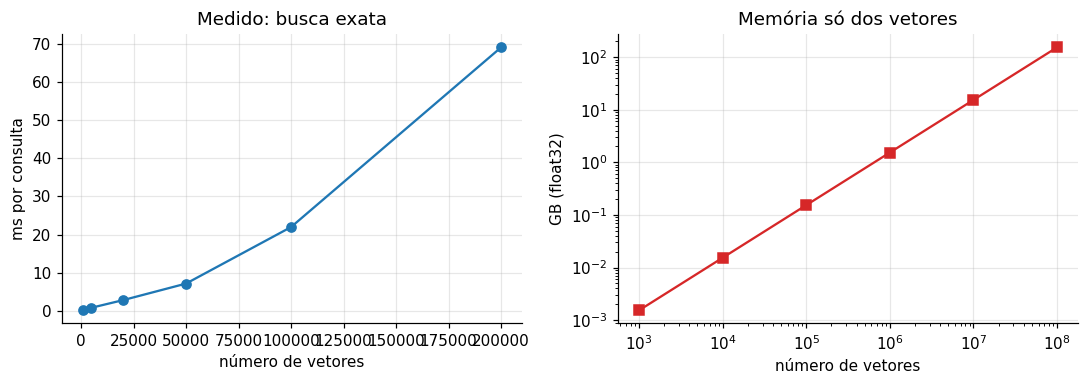

In [3]:
# Extrapolação para cenários maiores. ATENÇÃO: é uma conta de proporção, não uma medição.
# Ela supõe uma única máquina com memória suficiente, o que não ocorre nos cenários maiores.
cenarios = [("Hoje (protótipo)", 42), ("Cidade média (hipótese)", 1_000_000),
            ("Metrópole, 1 vetor por 1 cidadão (hipótese)", 12_000_000),
            ("Metrópole com histórico (hipótese)", 100_000_000)]

linhas = []
for nome, N in cenarios:
    memoria_gb = N * D * 4 / 1e9                    # float32 = 4 bytes por número
    linhas.append([nome, f"{N:,}".replace(",", "."), round(memoria_gb, 3),
                   round(max(a * N + b, 0) / 1000, 3)])
tab_cenarios = pd.DataFrame(linhas, columns=["cenário", "vetores", "memória só dos vetores (GB)",
                                             "tempo extrapolado por consulta (s)"])
display(tab_cenarios)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(TAMANHOS, tempos_ms, "o-")
ax[0].set_xlabel("número de vetores"); ax[0].set_ylabel("ms por consulta"); ax[0].set_title("Medido: busca exata")
Ns = np.array([1e3, 1e4, 1e5, 1e6, 1e7, 1e8])
ax[1].loglog(Ns, Ns * D * 4 / 1e9, "s-", color="tab:red")
ax[1].set_xlabel("número de vetores"); ax[1].set_ylabel("GB (float32)"); ax[1].set_title("Memória só dos vetores")
plt.tight_layout(); plt.savefig("figs/fig1_tempo_memoria.png", dpi=150); plt.show()

**O que ler desse resultado**

- O tempo da busca exata cresce de forma aproximadamente **linear** com o número de vetores, como esperado de uma comparação com todos os itens ($O(N)$). As medições do Colab oscilam entre execuções porque a CPU é compartilhada, então o formato exato da curva muda a cada rodada.
- A memória é um limite mais cedo do que o tempo. Cem milhões de vetores de 384 dimensões ocupam cerca de 150 GB só nos números, sem contar o índice, os textos e os metadados. Isso já obriga a dividir a base em várias máquinas (*sharding*).
- **Ressalva importante:** na prática ninguém usa busca exata em escala grande. Usam-se índices aproximados (HNSW, IVF), compressão de vetores e GPUs. Então o gargalo real não é "a IA clássica não consegue", e sim "a IA clássica só consegue com aproximação, e aproximar tem um preço". É isso que olhamos agora.

## 1.2 Preço da aproximação: velocidade contra recall

Para simular o que um índice aproximado faz, construímos um mini IVF (*inverted file*): os vetores são agrupados por k-means e, na hora da consulta, só olhamos os `nprobe` grupos mais próximos. Quanto menos grupos olhamos, mais rápido e menos preciso.

Montamos uma base sintética com dois tipos de assunto:
- **temas grandes** (muitos documentos, como zeladoria em geral);
- **subtemas pequenos colados em um tema grande** (poucos documentos, parecidos com um tema grande, como "gratuidade para PcD" ao lado de "transporte").

A pergunta que queremos responder é a mesma que fizemos no relatório de IA Generativa: a aproximação prejudica mais os assuntos pequenos? Deixamos o experimento decidir.

,nprobe,% da base varrida,recall@10 temas grandes,recall@10 subtemas pequenos
0,1,1.8,0.492,0.566
1,2,3.8,0.794,0.896
2,4,6.7,0.984,1.000
3,8,13.0,1.000,1.000
4,16,24.8,1.000,1.000


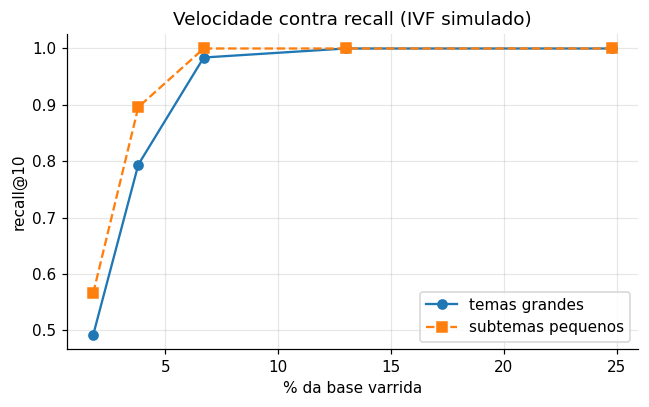

In [4]:
from sklearn.cluster import MiniBatchKMeans

def unit(v):
    return v / np.linalg.norm(v, axis=-1, keepdims=True)

rng2 = np.random.default_rng(SEED)
d = 64
n_grandes, n_sub = 20, 6
centros = unit(rng2.standard_normal((n_grandes + n_sub, d)))
for j in range(n_sub):                              # cada subtema nasce perto de um tema grande
    centros[n_grandes + j] = unit(centros[j] + 0.45 * unit(rng2.standard_normal(d)))
tamanhos = [4000] * n_grandes + [100] * n_sub       # 80 mil vetores nos temas grandes, 600 nos subtemas
ruido = 0.12

def sortear(c, n):
    return unit(centros[c] + ruido * rng2.standard_normal((n, d)))

base2 = np.vstack([sortear(c, n) for c, n in enumerate(tamanhos)]).astype("float32")
km = MiniBatchKMeans(n_clusters=64, n_init=3, batch_size=4096, random_state=SEED).fit(base2)
grupo_de = km.labels_
centroides = km.cluster_centers_.astype("float32")

def busca_aproximada(q, nprobe, k=10):
    grupos = np.argsort(-(centroides @ q))[:nprobe]          # escolhe os grupos mais próximos
    idx = np.where(np.isin(grupo_de, grupos))[0]             # só compara com quem está neles
    sim = base2[idx] @ q
    return idx[np.argsort(-sim)[:k]], len(idx) / len(base2)

def avaliar(grupo_de_temas, nprobe, n_consultas=200):
    rec, frac = [], []
    for c in rng2.choice(list(grupo_de_temas), n_consultas):
        q = sortear(c, 1)[0].astype("float32")               # consulta nova, fora da base
        exato = set(np.argsort(-(base2 @ q))[:10])           # resposta exata (verdade de referência)
        aprox, f = busca_aproximada(q, nprobe)
        rec.append(len(exato & set(aprox)) / 10); frac.append(f)
    return np.mean(rec), np.mean(frac)

linhas = []
for nprobe in [1, 2, 4, 8, 16]:
    rg, fg = avaliar(range(n_grandes), nprobe)
    rs, fs = avaliar(range(n_grandes, n_grandes + n_sub), nprobe)
    linhas.append([nprobe, round(100 * (fg + fs) / 2, 1), round(rg, 3), round(rs, 3)])
tab_recall = pd.DataFrame(linhas, columns=["nprobe", "% da base varrida", "recall@10 temas grandes",
                                           "recall@10 subtemas pequenos"])
display(tab_recall)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(tab_recall["% da base varrida"], tab_recall["recall@10 temas grandes"], "o-", label="temas grandes")
ax.plot(tab_recall["% da base varrida"], tab_recall["recall@10 subtemas pequenos"], "s--", label="subtemas pequenos")
ax.set_xlabel("% da base varrida"); ax.set_ylabel("recall@10"); ax.legend(); ax.set_title("Velocidade contra recall (IVF simulado)")
plt.tight_layout(); plt.savefig("figs/fig2_recall.png", dpi=150); plt.show()

**O que ler desse resultado**

- Existe o compromisso esperado: com 1 grupo varrido o recall@10 ficou perto de 0,5, e com 2 grupos ficou entre 0,79 e 0,90. Para passar de 0,98 foi preciso varrer cerca de 7% da base, o que ainda é uma economia grande em relação à busca exata.
- **A hipótese que levantamos no relatório de IA Generativa (viés de maioria, em que assuntos pequenos perdem mais recall) não se confirmou nesta simulação.** Os subtemas pequenos não ficaram piores: em `nprobe = 2` o recall deles foi até 0,10 maior que o dos temas grandes. Na nossa primeira execução, em outro ambiente, a diferença tinha o sinal oposto (até 0,07 a menos para os subtemas). Quando o sinal muda entre execuções, com 200 consultas por grupo, o mais provável é que seja ruído e não um efeito real.
- Isso muda a forma de apresentar o argumento. Dizer que "a busca aproximada esconde minorias" seria afirmar algo que não medimos. O que podemos dizer é que o risco de perder um trecho raro e necessário existe, que ele depende da base e do índice, e que **precisa ser medido com os dados reais** antes de qualquer conclusão. Um trecho perdido numa regra de exceção, em um caso de direito social, custa mais do que um trecho perdido numa pergunta comum.
- Também fica claro que o ganho da busca aproximada clássica é grande. **Qualquer proposta quântica precisa ser comparada com o ANN clássico, não com a busca exata.** Essa é a comparação honesta e ela torna o caso quântico mais difícil.

## 1.3 Segurança: o gargalo que não aparece nos gráficos

Os dois primeiros gargalos podem ser medidos em segundos e gigabytes. O terceiro é de outra natureza. À medida que o número de cidadãos atendidos cresce, cresce também o volume de dados pessoais guardados (histórico de conversa, cadastro, condição de deficiência, protocolos de denúncia). Dois pontos chamam atenção:

- **Superfície de ataque.** Uma base vetorial centralizada com dados de milhões de pessoas é um alvo mais valioso do que 11 manuais públicos.
- **Captura hoje, decifragem depois** (*harvest now, decrypt later*). Dados criptografados com RSA ou curvas elípticas e interceptados agora poderiam ser abertos no futuro por um computador quântico grande o bastante rodando o algoritmo de Shor. Para dado que precisa ficar protegido por décadas, o risco começa antes de existir o computador quântico.

Na Parte 4 transformamos isso em uma conta simples. Antes, vamos ver o que o quântico faria com a parte da busca.

# Parte 2. Busca quântica: Grover simulado em escala pequena

## 2.1 A ideia em poucas linhas

Imagine procurar um trecho específico entre $N$ trechos sem nenhuma organização. Um programa clássico, em média, precisa olhar cerca de $N/2$. O algoritmo de Grover (1996) usa **amplificação de amplitude**: começa com todos os itens em superposição e, a cada iteração, aumenta a probabilidade dos itens "marcados" e diminui a dos outros. Ele precisa de aproximadamente $\frac{\pi}{4}\sqrt{N}$ iterações. É um ganho **quadrático**, não exponencial.

Três limites que vamos manter à vista:

1. Grover precisa de um **oráculo**: um circuito que reconhece se um item é uma boa resposta. No nosso caso seria algo como "este trecho pertence à categoria PcD e à regra de calçada".
2. Passar do ponto de parada **piora** o resultado (a probabilidade oscila). É preciso conhecer ou estimar quantos itens estão marcados.
3. Os dados precisam estar acessíveis em superposição. Isso exige uma memória quântica de acesso aleatório (QRAM), que ainda não existe em escala útil. Voltamos a isso na Parte 4.

Abaixo implementamos Grover com vetores de estado em numpy. Com $n$ qubits temos $N = 2^n$ itens.

### Por que Grover e não Bernstein-Vazirani ou Simon

Em aula também foram executados Bernstein-Vazirani e Simon. Os três usam um oráculo, mas resolvem problemas diferentes e cada um exige uma **promessa** sobre a função:

| Algoritmo | O que resolve | Promessa exigida | Ganho |
|---|---|---|---|
| Bernstein-Vazirani | Descobrir uma sequência secreta $s$ de $n$ bits em $f(x) = s \cdot x \pmod 2$ | A função é exatamente desse tipo | 1 consulta, contra $n$ no clássico |
| Simon | Descobrir um período oculto $s$ tal que $f(x) = f(x \oplus s)$ | A função repete valores com esse padrão | Exponencial em consultas ao oráculo, em relação aos algoritmos clássicos probabilísticos |
| Grover | Achar itens que satisfazem uma condição em uma base sem estrutura | Só um oráculo que reconheça uma boa resposta | Quadrático, cerca de $\sqrt{N}$ |

Documentos e embeddings do CitizenTech não escondem uma função linear nem um período. O problema real é achar os trechos que atendem a uma condição ("PcD, calçada e gratuidade") em uma base sem estrutura, e isso só se encaixa no Grover. **Escolhemos pela aderência ao problema, não pelo tamanho do ganho:** o ganho do Grover é o menor dos três, e as simulações abaixo mostram o preço disso. Uma ligação com outra parte do trabalho: a ideia de período oculto do Simon é precursora do algoritmo de Shor, que é a ameaça tratada na Parte 4.2 (criptografia pós-quântica), mas ela não ajuda na recuperação de trechos.

,qubits,itens (N),"clássico, média de consultas","Grover, iterações",prob. de acerto
0,2,4,2.5,1,1.0000
1,4,16,8.5,3,0.9613
2,6,64,32.5,6,0.9966
3,8,256,128.5,12,0.9999
4,10,1024,512.5,25,0.9995
5,12,4096,2048.5,50,0.9999
6,14,16384,8192.5,100,1.0000


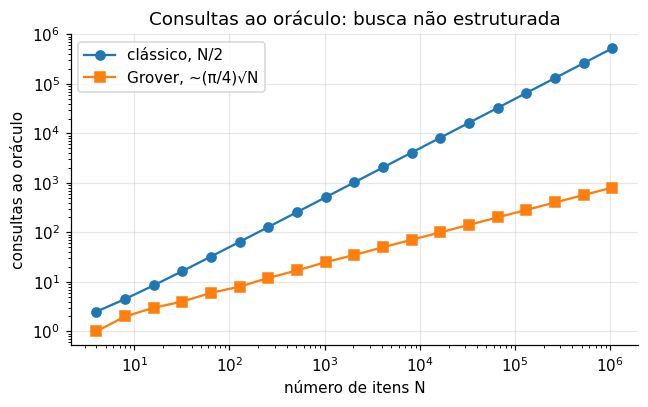

In [5]:
def iteracoes_otimas(N, M=1):
    """Número de iterações de Grover com M itens marcados entre N."""
    theta = math.asin(math.sqrt(M / N))
    return max(1, round(math.pi / (4 * theta) - 0.5))

def grover(n_qubits, marcados, iteracoes=None):
    """Simula Grover com vetor de estado. Devolve o estado final e a probabilidade de acerto a cada passo."""
    N = 2 ** n_qubits
    marcados = np.array(marcados)
    k = iteracoes if iteracoes is not None else iteracoes_otimas(N, len(marcados))
    psi = np.full(N, 1 / np.sqrt(N))                  # superposição uniforme (portas Hadamard)
    historico = [float(np.sum(psi[marcados] ** 2))]
    for _ in range(k):
        psi[marcados] *= -1                           # oráculo: troca o sinal dos itens marcados
        psi = 2 * psi.mean() - psi                    # difusão: inversão em torno da média
        historico.append(float(np.sum(psi[marcados] ** 2)))
    return psi, historico

# Quantas consultas ao oráculo cada abordagem pede, com 1 item marcado
linhas = []
for n in range(2, 15, 2):
    N = 2 ** n
    k = iteracoes_otimas(N)
    _, h = grover(n, [N - 1])
    linhas.append([n, N, (N + 1) / 2, k, round(h[-1], 4)])
tab_grover = pd.DataFrame(linhas, columns=["qubits", "itens (N)", "clássico, média de consultas",
                                           "Grover, iterações", "prob. de acerto"])
display(tab_grover)

Ns = 2 ** np.arange(2, 21)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.loglog(Ns, (Ns + 1) / 2, "o-", label="clássico, N/2")
ax.loglog(Ns, [iteracoes_otimas(int(N)) for N in Ns], "s-", label="Grover, ~(π/4)√N")
ax.set_xlabel("número de itens N"); ax.set_ylabel("consultas ao oráculo"); ax.legend()
ax.set_title("Consultas ao oráculo: busca não estruturada")
plt.tight_layout(); plt.savefig("figs/fig3_grover_escala.png", dpi=150); plt.show()

## 2.2 O caso do CitizenTech em miniatura

Para ligar com o projeto, montamos um catálogo de brinquedo com os 11 documentos do corpus mais 5 posições vazias, totalizando 16 itens, que cabem em 4 qubits. Imaginamos a consulta de uma pessoa com deficiência que quer, ao mesmo tempo, **adaptação de calçada** (documento 05) e **gratuidade no transporte** (documento 06). O oráculo marca esses dois documentos.

Com 2 itens marcados entre 16, o número ótimo de iterações é 2. Veja também o que acontece com uma iteração a mais.

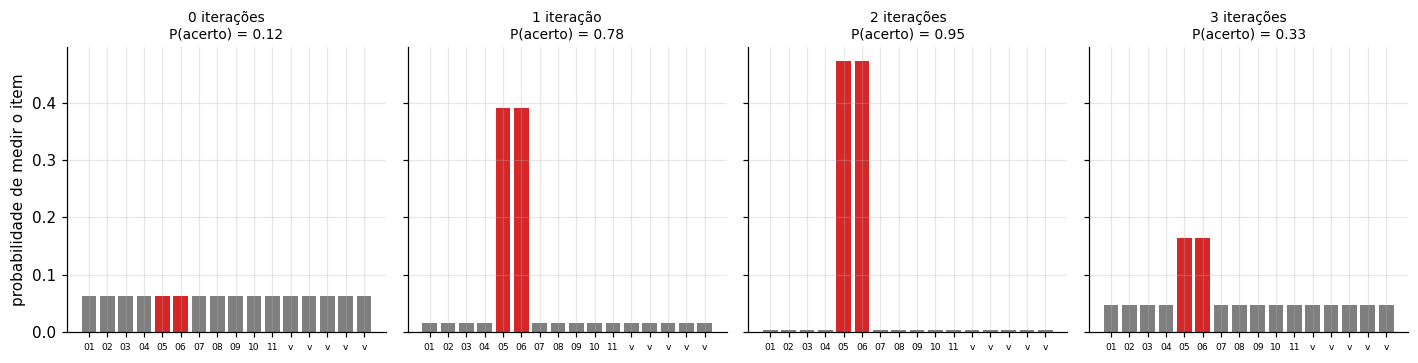

Iterações ótimas para N=16 e M=2: 2
Probabilidade de acerto por iteração (0 a 6): [0.125 0.781 0.945 0.33  0.012 0.548 1.   ]


In [6]:
catalogo = ["01 tapa-buraco", "02 iluminação", "03 entulho e móveis", "04 poda de árvores", "05 acessib. calçadas",
            "06 gratuidade PcD", "07 vagas idosos/PcD", "08 IPTU", "09 ouvidoria", "10 proteção de dados",
            "11 atendimento presencial"] + [f"(vazio {i})" for i in range(1, 6)]
marcados = [4, 5]                                    # documentos 05 e 06
n = 4

fig, axs = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for k, ax in zip([0, 1, 2, 3], axs):
    psi, h = grover(n, marcados, iteracoes=k)
    cores = ["tab:red" if i in marcados else "tab:gray" for i in range(16)]
    ax.bar(range(16), psi ** 2, color=cores)
    ax.set_title(f"{k} {'iteração' if k == 1 else 'iterações'}\nP(acerto) = {h[-1]:.2f}", fontsize=9)
    ax.set_xticks(range(16)); ax.set_xticklabels([c[:2] if c[0].isdigit() else "v" for c in catalogo], fontsize=6)   # v = posição vazia
axs[0].set_ylabel("probabilidade de medir o item")
plt.tight_layout(); plt.savefig("figs/fig4_grover_catalogo.png", dpi=150); plt.show()

print("Iterações ótimas para N=16 e M=2:", iteracoes_otimas(16, 2))
print("Probabilidade de acerto por iteração (0 a 6):", np.round(grover(4, marcados, iteracoes=6)[1], 3))

**O que ler desse resultado**

- Com 2 iterações a probabilidade de medir um dos dois documentos corretos passa de 90%. Com 3 ela cai: **mais iterações não é melhor**. Em um sistema real isso significa que o algoritmo exige saber, ao menos de forma aproximada, quantos resultados são esperados.
- Para 16 itens a diferença para a busca clássica é pequena (2 iterações contra cerca de 6 comparações em média para achar um dos dois). O ganho só importa quando $N$ é grande, e nesse regime a dificuldade passa a ser o hardware, não o algoritmo.
- O resultado de Grover é uma **medição probabilística**. Para o cidadão isso quer dizer que a resposta precisa ser verificada e que o sistema precisa de um limiar de confiança, como já temos em `calibration.py`.

## 2.3 Conferindo a simulação com o Qiskit

Para não depender só do nosso código, montamos o mesmo circuito no Qiskit (biblioteca padrão de computação quântica) e comparamos as probabilidades. Esse circuito também poderia ser enviado a um simulador ou a um computador quântico real em nuvem, desde que tivesse poucos qubits.

In [7]:
from qiskit import QuantumCircuit
try:
    from qiskit.circuit.library import DiagonalGate as Diagonal   # nome novo (Qiskit 2.1 em diante)
except ImportError:
    from qiskit.circuit.library import Diagonal                   # nome antigo
from qiskit.quantum_info import Statevector

def circuito_grover(n, marcados, k):
    N = 2 ** n
    oraculo = [-1 if i in marcados else 1 for i in range(N)]   # inverte a fase dos itens marcados
    difusao = [1] + [-1] * (N - 1)                              # inverte a fase de tudo menos |0...0>
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for _ in range(k):
        qc.append(Diagonal(oraculo), range(n))
        qc.h(range(n)); qc.append(Diagonal(difusao), range(n)); qc.h(range(n))
    return qc

qc = circuito_grover(4, marcados, 2)
p_qiskit = Statevector(qc).probabilities()
p_numpy = grover(4, marcados, iteracoes=2)[0] ** 2

print("Maior diferença entre nosso código e o Qiskit:", float(np.max(np.abs(p_qiskit - p_numpy))))
contagens = Statevector(qc).sample_counts(shots=1024)            # simula 1024 execuções do circuito
resumo = sorted(((int(b, 2), c) for b, c in contagens.items()), key=lambda x: -x[1])[:4]
print("Resultados mais frequentes em 1024 execuções (item, contagem):", [(catalogo[i], int(c)) for i, c in resumo])

Maior diferença entre nosso código e o Qiskit: 2.275957200481571e-15
Resultados mais frequentes em 1024 execuções (item, contagem): [('06 gratuidade PcD', 490), ('05 acessib. calçadas', 465), ('01 tapa-buraco', 9), ('08 IPTU', 8)]


### 2.3.1 Grover montado porta a porta com `QuantumCircuit`

Na seção 2.3 o circuito usou a porta `Diagonal` como atalho para o oráculo e o difusor. Aqui montamos o mesmo algoritmo do jeito que foi feito em aula, com portas básicas, e **executamos o circuito com medição e shots** em um simulador do Qiskit (`AerSimulator`).

Ciclo do circuito, igual ao da aula: preparação, evolução unitária, medição, informação clássica.

| Etapa | Portas usadas |
|---|---|
| Preparação | `H` em todos os qubits (superposição uniforme dos 16 itens) |
| Oráculo de fase | `X` nos qubits que devem valer 0, `H` + `CCX` + `H` (equivale a um `CCZ`) e `X` de volta |
| Difusor | `H`, `X`, `H` + `MCX` + `H`, `X`, `H` (inversão em torno da média) |
| Medição | `measure` dos 4 qubits em 4 bits clássicos |

O oráculo marca os itens 4 e 5 do catálogo (documentos 05 e 06), que no Qiskit correspondem às cadeias de bits `0100` e `0101`. O Qiskit escreve os bits do qubit 3 para o qubit 0, então o qubit 0 pode valer 0 ou 1 e os qubits 3, 2 e 1 valem 0, 1 e 0.

Instalando qiskit-aer
Instalando pylatexenc


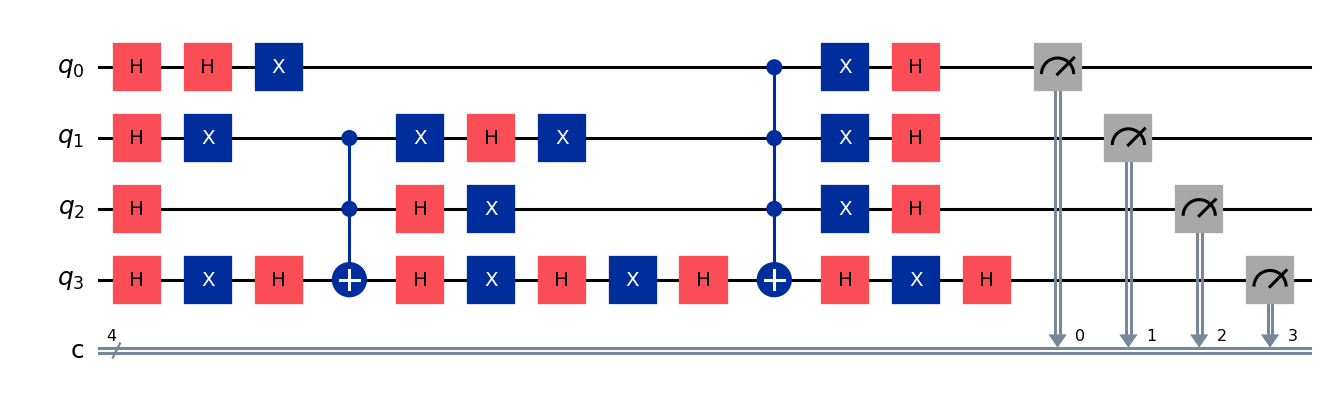

,iterações,P(acerto) medida (1024 shots),P(acerto) teórica
0,1,0.819,0.781
1,2,0.961,0.945
2,3,0.341,0.330


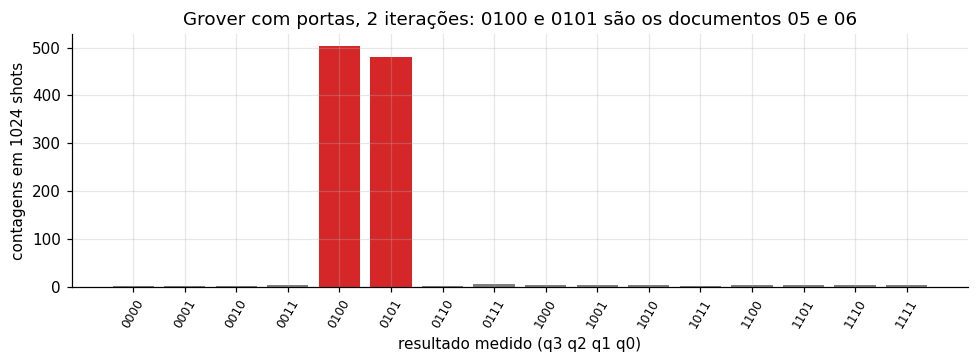

In [8]:
# Grover com portas, como em aula: H, oráculo de fase, difusor e medição
garantir("qiskit-aer", "qiskit_aer")                      # no Colab o Aer costuma faltar
garantir("pylatexenc")                                     # necessário para desenhar o circuito com matplotlib
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector

try:
    from qiskit_aer import AerSimulator
    simulador = AerSimulator()
except Exception as erro:                                  # plano B se o Aer não instalar
    simulador = None
    print("AerSimulator indisponível, usando Statevector:", erro)

def grover_com_portas(k):
    """Circuito de Grover com 4 qubits e k iterações, marcando os bits 0100 e 0101."""
    qc = QuantumCircuit(4, 4)
    qc.h(range(4))                                         # preparação: superposição uniforme
    for _ in range(k):
        # oráculo de fase: inverte o sinal de q3 q2 q1 = 0 1 0 (q0 livre)
        qc.x([1, 3])                                       # transforma os zeros em uns
        qc.h(3); qc.ccx(1, 2, 3); qc.h(3)                  # H + CCX + H equivale a um CCZ
        qc.x([1, 3])                                       # desfaz os X
        # difusor: inversão em torno da média
        qc.h(range(4)); qc.x(range(4))
        qc.h(3); qc.mcx([0, 1, 2], 3); qc.h(3)
        qc.x(range(4)); qc.h(range(4))
    qc.measure(range(4), range(4))                         # medição: 4 qubits em 4 bits clássicos
    return qc

SHOTS = 1024
MARCADOS_BITS = {"0100", "0101"}                           # documentos 05 e 06

def executar(qc):
    """Executa o circuito com shots e devolve as contagens."""
    if simulador is not None:
        return simulador.run(transpile(qc, simulador), shots=SHOTS, seed_simulator=SEED).result().get_counts()
    return Statevector(qc.remove_final_measurements(inplace=False)).sample_counts(shots=SHOTS)

# Desenho do circuito com 1 iteração (o circuito com 2 iterações repete o bloco central duas vezes)
qc2 = grover_com_portas(2)
qc1 = grover_com_portas(1)
try:
    fig_circ = qc1.draw("mpl", fold=-1)
    fig_circ.savefig("figs/fig8_circuito_grover.png", dpi=150, bbox_inches="tight")
    display(fig_circ)
except Exception:
    print(qc1.draw("text", fold=140))                      # sem matplotlib/pylatexenc, desenha em texto

# Probabilidade de acerto medida (shots) contra a teórica (vetor de estado), para 1, 2 e 3 iterações
linhas = []
for k in [1, 2, 3]:
    qc = grover_com_portas(k)
    contagens = executar(qc)
    p_medida = sum(c for bits, c in contagens.items() if bits in MARCADOS_BITS) / SHOTS
    p_teorica = sum(p for bits, p in Statevector(qc.remove_final_measurements(inplace=False)).probabilities_dict().items()
                    if bits in MARCADOS_BITS)
    linhas.append([k, round(p_medida, 3), round(p_teorica, 3)])
display(pd.DataFrame(linhas, columns=["iterações", f"P(acerto) medida ({SHOTS} shots)", "P(acerto) teórica"]))

# Histograma das contagens com 2 iterações
contagens2 = executar(qc2)
bits_ordenados = sorted(f"{i:04b}" for i in range(16))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(bits_ordenados, [contagens2.get(b, 0) for b in bits_ordenados],
       color=["tab:red" if b in MARCADOS_BITS else "tab:gray" for b in bits_ordenados])
ax.set_xlabel("resultado medido (q3 q2 q1 q0)"); ax.set_ylabel(f"contagens em {SHOTS} shots")
ax.set_title("Grover com portas, 2 iterações: 0100 e 0101 são os documentos 05 e 06")
plt.xticks(rotation=60, fontsize=8); plt.tight_layout()
plt.savefig("figs/fig9_contagens_grover.png", dpi=150); plt.show()

**O que ler desse resultado**

- O circuito montado com portas e **medido com shots** concorda com o vetor de estado: com 2 iterações a probabilidade medida de obter os documentos 05 ou 06 foi de cerca de 0,96 (teórica 0,945), e com 3 iterações caiu para cerca de 0,34 (teórica 0,33). A pequena diferença vem da amostragem de 1.024 shots.
- É o mesmo comportamento da seção 2.2: a 2ª iteração é o ponto ideal e a 3ª piora o resultado. Agora ele aparece como contagem de medições, que é o que um computador quântico entregaria.
- Este simulador é ideal, sem ruído de hardware. O efeito do ruído está na seção 2.4.

## 2.4 O que muda com ruído

Computadores quânticos atuais cometem erros a cada porta. Com muitas iterações, o ruído acumulado destrói a vantagem. Para ter uma ideia, usamos um modelo simples: a cada iteração, com probabilidade $p$, o estado é trocado por um estado totalmente aleatório (ruído despolarizante global). Esse modelo é uma simplificação, mas mostra a tendência.

Escolhemos $n = 10$ qubits (1.024 itens, 1 marcado), cujo ponto ótimo sem ruído é de 25 iterações.

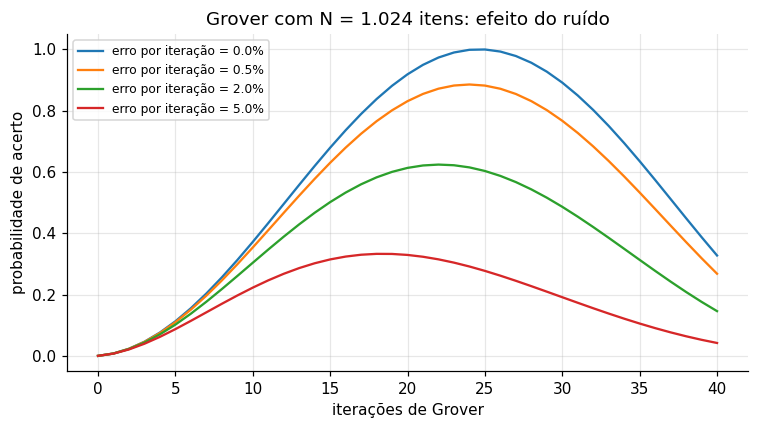

,erro por iteração,melhor nº de iterações,melhor prob. de acerto
0,0.0%,25,0.999
1,0.5%,24,0.885
2,2.0%,22,0.624
3,5.0%,18,0.333


In [9]:
def grover_com_ruido(n, marcado, p, k_max):
    """Probabilidade de acerto a cada iteração quando cada iteração mistura o estado com ruído uniforme.
    Como a mistura com o estado totalmente aleatório comuta com as portas, basta combinar duas contas:
    P = f * P_sem_ruido + (1 - f) / N, com f = (1 - p) ** k."""
    N = 2 ** n
    _, h = grover(n, [marcado], iteracoes=k_max)
    k = np.arange(k_max + 1)
    f = (1 - p) ** k
    return f * np.array(h) + (1 - f) / N

n = 10
k_max = 40
fig, ax = plt.subplots(figsize=(7, 4))
linhas = []
for p in [0, 0.005, 0.02, 0.05]:
    prob = grover_com_ruido(n, 5, p, k_max)
    ax.plot(prob, label=f"erro por iteração = {p*100:.1f}%")
    linhas.append([f"{p*100:.1f}%", int(np.argmax(prob)), round(float(prob.max()), 3)])
ax.set_xlabel("iterações de Grover"); ax.set_ylabel("probabilidade de acerto")
ax.set_title("Grover com N = 1.024 itens: efeito do ruído"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/fig5_ruido.png", dpi=150); plt.show()
display(pd.DataFrame(linhas, columns=["erro por iteração", "melhor nº de iterações", "melhor prob. de acerto"]))

**O que ler desse resultado**

- Sem ruído, a melhor probabilidade fica perto de 1 com 25 iterações. Com erro de 0,5% por iteração a probabilidade máxima cai para cerca de 0,89, com 2% cai para cerca de 0,62 e com 5% para cerca de 0,33, e o melhor ponto de parada chega mais cedo.
- É por isso que o roadmap não coloca ganho quântico de busca no curto prazo. A era NISQ (qubits ruidosos e poucos) não sustenta circuitos profundos, e um oráculo que consulte uma base real é profundo. Seria preciso correção de erros, o que a literatura trata como o marco da computação tolerante a falhas.
- O modelo de ruído é simples demais para prever hardware real. Ele serve para mostrar o sentido do efeito, não a magnitude exata.

# Parte 3. Re-ranqueamento por similaridade: o *swap test*

Grover acha itens que satisfazem uma condição. Já o nosso RAG precisa **ordenar** trechos por similaridade semântica. Uma peça que existe para isso é o *swap test*: um circuito pequeno que estima o quanto dois estados quânticos se parecem, medindo apenas um qubit auxiliar. Se codificamos dois vetores normalizados $a$ e $b$ como estados, a probabilidade de medir 0 no qubit auxiliar é

$$P(0) = \frac{1 + |\langle a | b \rangle|^2}{2}.$$

Ou seja, medir muitas vezes (*shots*) permite estimar o produto interno ao quadrado. A ideia de arquitetura que defendemos no relatório é **híbrida**: a parte clássica filtra por metadados e reduz milhões de registros a algumas dezenas de candidatos, e só nesses candidatos a parte quântica faria o re-ranqueamento fino.

Vamos simular isso em pequena escala, com os 11 documentos do corpus e vetores de 8 dimensões (3 qubits).

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Resumos curtos escritos para este notebook a partir dos 11 documentos do corpus (o corpus do protótipo é sintético)
resumos = {
 "01 tapa-buraco": "reparo de buraco na rua e no asfalto, prazo de atendimento do tapa buraco, como solicitar pelo canal oficial",
 "02 iluminação": "poste apagado ou lâmpada queimada na rua, manutenção da iluminação pública, como solicitar o reparo",
 "03 entulho e móveis": "coleta de entulho e de móveis velhos, agendamento da retirada, onde descartar materiais",
 "04 poda de árvores": "poda de árvore e retirada de galhos, autorização, risco de queda de árvore na calçada",
 "05 acessib. calçadas": "calçada acessível, rampa de acesso, piso tátil, solicitar adaptação da calçada para pessoa com deficiência",
 "06 gratuidade PcD": "gratuidade no transporte público para pessoa com deficiência, documentos, laudo, cadastro e renovação do benefício",
 "07 vagas idosos/PcD": "vagas especiais de estacionamento para idosos e pessoas com deficiência, credencial e fiscalização",
 "08 IPTU": "IPTU, isenção e desconto, prazo de pagamento, imposto sobre imóvel, quem tem direito à isenção",
 "09 ouvidoria": "ouvidoria, denúncia e reclamação, acompanhar protocolo, prazo de resposta ao cidadão",
 "10 proteção de dados": "proteção de dados pessoais, LGPD, quais dados o assistente coleta, como o cidadão pede acesso ou exclusão",
 "11 atendimento presencial": "atendimento presencial nas unidades, agendamento, documentos necessários, horário de funcionamento",
}
nomes = list(resumos.keys())
tfidf = TfidfVectorizer(strip_accents="unicode", lowercase=True)
Xtf = tfidf.fit_transform(resumos.values())
nmf = NMF(n_components=8, init="nndsvda", random_state=SEED, max_iter=2000)   # 8 dimensões, todas não negativas
W = nmf.fit_transform(Xtf)
V = unit(W + 1e-12)                                      # vetores dos documentos, normalizados

consulta = "sou pessoa com deficiência e preciso de rampa na calçada e de gratuidade no transporte"
q = unit(nmf.transform(tfidf.transform([consulta]))[0] + 1e-12)

cos = V @ q                                              # similaridade clássica (cosseno, sempre >= 0 aqui)
F = cos ** 2                                             # é isto que o swap test estima
ordem = np.argsort(-cos)
tab_rank = pd.DataFrame({"documento": [nomes[i] for i in ordem], "cosseno": np.round(cos[ordem], 3),
                         "cosseno²": np.round(F[ordem], 3)})
display(tab_rank.head(6))

,documento,cosseno,cosseno²
0,05 acessib. calçadas,0.981,0.963
1,06 gratuidade PcD,0.954,0.911
2,04 poda de árvores,0.216,0.047
3,03 entulho e móveis,0.204,0.042
4,01 tapa-buraco,0.195,0.038
5,02 iluminação,0.162,0.026


,shots por par,execuções de circuito no total,mesmo 1º lugar que o clássico,docs 05 e 06 nos 2 primeiros,mesmos 3 primeiros que o clássico
0,50,550,0.67,1.0,0.15
1,500,5500,0.99,1.0,0.22
2,5000,55000,1.00,1.0,0.49
3,50000,550000,1.00,1.0,0.75


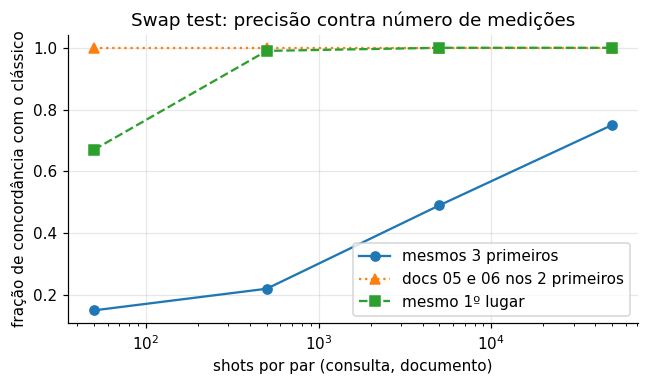

In [11]:
# Swap test simulado: P(0) = (1 + cos²) / 2. Cada "shot" é uma medição do qubit auxiliar.
def swap_test_estimativa(F_verdadeiro, shots, gerador):
    p0 = (1 + F_verdadeiro) / 2
    p0_hat = gerador.binomial(shots, p0) / shots
    return np.clip(2 * p0_hat - 1, 0, 1)                 # estimativa de cos²

gen = np.random.default_rng(SEED)
top3_classico = set(ordem[:3])
linhas = []
for shots in [50, 500, 5_000, 50_000]:
    acerto_top1, acerto_top3, acerto_rel = 0, 0, 0
    relevantes = {nomes.index("05 acessib. calçadas"), nomes.index("06 gratuidade PcD")}
    for _ in range(300):
        est = np.array([swap_test_estimativa(f, shots, gen) for f in F])
        o = np.argsort(-est)
        acerto_top1 += (o[0] == ordem[0])
        acerto_top3 += (set(o[:3]) == top3_classico)
        acerto_rel += (set(o[:2]) == relevantes)
    linhas.append([shots, shots * len(nomes), round(acerto_top1 / 300, 2), round(acerto_rel / 300, 2), round(acerto_top3 / 300, 2)])
tab_shots = pd.DataFrame(linhas, columns=["shots por par", "execuções de circuito no total",
                                          "mesmo 1º lugar que o clássico", "docs 05 e 06 nos 2 primeiros",
                                          "mesmos 3 primeiros que o clássico"])
display(tab_shots)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogx(tab_shots["shots por par"], tab_shots["mesmos 3 primeiros que o clássico"], "o-", label="mesmos 3 primeiros")
ax.semilogx(tab_shots["shots por par"], tab_shots["docs 05 e 06 nos 2 primeiros"], "^:", label="docs 05 e 06 nos 2 primeiros")
ax.semilogx(tab_shots["shots por par"], tab_shots["mesmo 1º lugar que o clássico"], "s--", label="mesmo 1º lugar")
ax.set_xlabel("shots por par (consulta, documento)"); ax.set_ylabel("fração de concordância com o clássico")
ax.set_title("Swap test: precisão contra número de medições"); ax.legend()
plt.tight_layout(); plt.savefig("figs/fig6_swap_test.png", dpi=150); plt.show()

In [12]:
# Conferência com o Qiskit: um swap test de verdade para um par (consulta, documento 06)
def swap_test_qiskit(a, b):
    qc = QuantumCircuit(7)                                  # 1 auxiliar + 3 qubits para a + 3 qubits para b
    qc.prepare_state(a, [1, 2, 3])                      # codificação por amplitude (assume que isso é possível)
    qc.prepare_state(b, [4, 5, 6])
    qc.h(0)
    for i in range(3):
        qc.cswap(0, 1 + i, 4 + i)
    qc.h(0)
    return Statevector(qc).probabilities([0])[0]            # P(auxiliar = 0)

i06 = nomes.index("06 gratuidade PcD")
p0_qiskit = swap_test_qiskit(q, V[i06])
p0_formula = (1 + (q @ V[i06]) ** 2) / 2
print(f"P(0) pelo Qiskit: {p0_qiskit:.4f} | pela fórmula (1+cos²)/2: {p0_formula:.4f}")

P(0) pelo Qiskit: 0.9555 | pela fórmula (1+cos²)/2: 0.9555


**O que ler desse resultado**

- O 1º lugar se estabiliza com cerca de 500 medições por par. Já a ordem entre candidatos com similaridade parecida continua instável: o 3º, 4º e 5º colocados têm cosseno² entre 0,038 e 0,047, e mesmo com 50 mil medições por par os 3 primeiros coincidem com os do clássico em cerca de 75% das tentativas. O erro de estimativa cai com $1/\sqrt{\text{shots}}$, então distinguir diferenças pequenas fica caro.
- Isso toca diretamente a promessa de "re-ranqueamento fino": é justamente nas diferenças finas que o swap test pede mais medições. Para o nosso caso o essencial é que os dois documentos relevantes (05 e 06) apareçam no topo, e isso aconteceu em todas as tentativas, mesmo com 50 medições por par, porque a distância deles para o 3º colocado é grande (0,96 e 0,91 contra 0,05).
- Em um computador clássico, os 11 produtos internos são feitos em microssegundos. O swap test precisa de centenas de execuções de circuito para separar os documentos relevantes dos demais e de centenas de milhares para ordenar os candidatos parecidos entre si. **Hoje, nesta escala, o quântico perde por uma margem grande.**
- O ponto é outro: o swap test é uma peça que, combinada com busca de máximo quântica (Dürr e Høyer, 1996) e com memória quântica, poderia comparar a consulta com muitos candidatos em superposição. Aí o número de operações poderia crescer menos que $N$. Isso é uma projeção que depende de peças que ainda não existem, não algo que o notebook demonstre.
- Há mais um custo escondido: codificar um vetor como amplitudes (`prepare_state` acima) não é de graça. Em geral é uma operação que cresce com a dimensão do vetor. Escondemos isso no código usando um simulador.

# Parte 4. O que decide a viabilidade: QRAM e criptografia pós-quântica

## 4.1 O gargalo da QRAM, em números

Grover só tem ganho de $\sqrt{N}$ se os $N$ itens já estiverem disponíveis em superposição. Se for preciso carregar os dados item por item, o custo de carga é $O(N)$ e o ganho desaparece. O gráfico abaixo compara os três casos em operações, sem unidade de tempo, só para mostrar a ordem de grandeza.

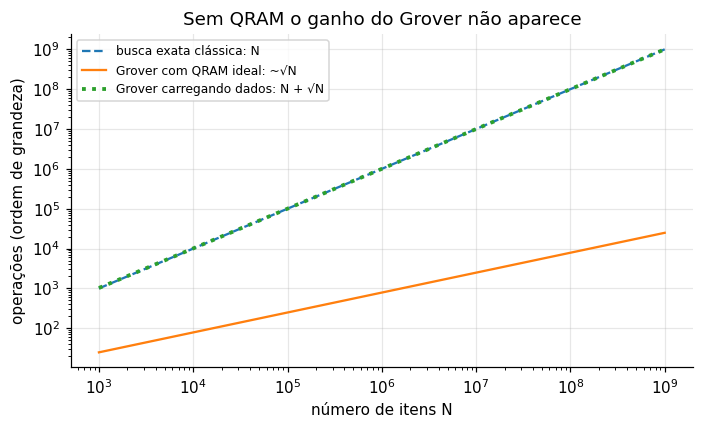

In [13]:
Ns = np.logspace(3, 9, 50)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(Ns, Ns, "--", label="busca exata clássica: N")
ax.loglog(Ns, np.sqrt(Ns) * math.pi / 4, label="Grover com QRAM ideal: ~√N")
ax.loglog(Ns, Ns + np.sqrt(Ns) * math.pi / 4, ":", linewidth=2.5, label="Grover carregando dados: N + √N")
ax.set_xlabel("número de itens N"); ax.set_ylabel("operações (ordem de grandeza)")
ax.set_title("Sem QRAM o ganho do Grover não aparece"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/fig7_qram.png", dpi=150); plt.show()

A curva de "Grover carregando dados" praticamente cobre a da busca clássica. Por isso o roadmap só coloca busca quântica sobre a base inteira no longo prazo, condicionada a existir QRAM viável. Antes disso, a parte quântica só faz sentido sobre **conjuntos pequenos de candidatos**, depois de um filtro clássico.

Duas observações adicionais, para manter o argumento equilibrado:

- Para problemas de recomendação e de aprendizado de máquina que se apoiam em amostragem, existem algoritmos clássicos "inspirados em quântica" (Tang, 2018) que reduzem boa parte da vantagem prometida. Isso significa que parte do ganho esperado pode vir de algoritmos clássicos melhores.
- Índices aproximados clássicos (HNSW, IVF) já fazem buscas em tempo bem menor que $N$. Por isso medimos o caso quântico contra eles, e não contra a busca exata.

## 4.2 Criptografia pós-quântica: a parte que podemos fazer antes

A criptografia pós-quântica (PQC) é outra capacidade quântica, mas ela funciona ao contrário: é a defesa **contra** o computador quântico e roda em computador comum. O NIST publicou em agosto de 2024 os primeiros padrões (FIPS 203, ML-KEM para troca de chaves; FIPS 204, ML-DSA, e FIPS 205, SLH-DSA, para assinaturas). Escolhemos Busca em Grandes Bases como capacidade principal, mas a PQC entra no roadmap como medida de curto prazo porque trata o gargalo de segurança sem esperar hardware novo.

Uma forma de organizar a decisão é a desigualdade de Mosca: há risco quando

$$X + Y > Z,$$

sendo $X$ o tempo em que o dado precisa continuar secreto, $Y$ o tempo que a organização leva para migrar a criptografia e $Z$ o tempo até existir um computador quântico capaz de quebrar a criptografia atual. **Ninguém sabe $Z$.** Os valores abaixo são hipóteses do grupo, para ilustrar o raciocínio, e não previsões.

In [14]:
# Prazos de sigilo (X) são hipóteses do grupo, por tipo de dado do assistente
dados = [
    ("Cadastro com condição de deficiência (dado sensível)", 30),
    ("Dados de IPTU e situação fiscal", 10),
    ("Protocolos de ouvidoria e denúncias", 15),
    ("Histórico de conversas mascarado", 5),
    ("Manuais de serviço (públicos)", 0),
]
Y = 4                                                      # hipótese: anos para migrar o sistema para PQC
cenarios_Z = [10, 15, 20]                                  # hipóteses para o tempo até um computador quântico relevante

linhas = []
for nome, X in dados:
    linha = [nome, X]
    for Z in cenarios_Z:
        linha.append("em risco" if X + Y > Z else "ok")
    linhas.append(linha)
tab_mosca = pd.DataFrame(linhas, columns=["tipo de dado", "X (anos de sigilo)"] + [f"Z = {z} anos" for z in cenarios_Z])
display(tab_mosca)
print("Y (migração) usado:", Y, "anos")

,tipo de dado,X (anos de sigilo),Z = 10 anos,Z = 15 anos,Z = 20 anos
0,Cadastro com condição de deficiência (dado sen...,30,em risco,em risco,em risco
1,Dados de IPTU e situação fiscal,10,em risco,ok,ok
2,Protocolos de ouvidoria e denúncias,15,em risco,em risco,ok
3,Histórico de conversas mascarado,5,ok,ok,ok
4,Manuais de serviço (públicos),0,ok,ok,ok


Y (migração) usado: 4 anos


O que a tabela mostra é qualitativo: dados de vida longa, como condição de deficiência, entram na zona de risco mesmo em cenários otimistas para o quântico, e dados públicos não entram em nenhum. Isso orienta a **ordem de migração**: começar pelo cadastro e pelos protocolos, e não pelos manuais.

# Parte 5. Resumo do roadmap e conclusões

In [15]:
roadmap = pd.DataFrame([
 ["Curto prazo (2026 a 2027)", "NISQ e preparação",
  "RAG sobre as 11 bases, avaliação com Hit@k e MRR, mascaramento de dados pessoais, inventário de criptografia, migração planejada para PQC",
  "Nenhum ganho quântico em busca. Preparação: particionar a base e medir o ANN real",
  "Atendimento rastreável e dados de longa vida protegidos contra captura futura",
  "Risco: resposta errada sobre direito social (revisão humana). LGPD: minimização, mascaramento, relatório de impacto. ODS 10, 16"],
 ["Médio prazo (2028 a 2032)", "Híbrido, início da tolerância a falhas",
  "Filtro por metadados e índice ANN reduzem milhões de registros a k candidatos",
  "Piloto de re-ranqueamento quântico (Grover e swap test) em QPU de nuvem sobre candidatos, com dados anonimizados, comparado ao clássico",
  "Menos respostas incompletas em casos com várias regras cruzadas, se o piloto mostrar ganho",
  "Risco: dependência de provedor e resultado probabilístico. LGPD: art. 33, anonimização, registro dos envios. ODS 9, 10, 16"],
 ["Longo prazo (2033 em diante)", "Tolerância a falhas e QRAM, se existirem",
  "Orquestração da conversa, geração de texto e sensores urbanos",
  "Busca quântica sobre bases grandes, condicionada a QRAM viável",
  "Orientação mais personalizada e sem fila, dependente de condições técnicas ainda incertas",
  "Risco: concentração de dados e vigilância (auditoria independente). LGPD: finalidade e uso compartilhado. ODS 9, 11, 16"],
], columns=["horizonte", "estágio tecnológico", "IA clássica", "quântico", "benefício ao cidadão", "ética, LGPD e ODS"])
pd.set_option("display.max_colwidth", 200)
display(roadmap)

,horizonte,estágio tecnológico,IA clássica,quântico,benefício ao cidadão,"ética, LGPD e ODS"
0,Curto prazo (2026 a 2027),NISQ e preparação,"RAG sobre as 11 bases, avaliação com Hit@k e MRR, mascaramento de dados pessoais, inventário de criptografia, migração planejada para PQC",Nenhum ganho quântico em busca. Preparação: particionar a base e medir o ANN real,Atendimento rastreável e dados de longa vida protegidos contra captura futura,"Risco: resposta errada sobre direito social (revisão humana). LGPD: minimização, mascaramento, relatório de impacto. ODS 10, 16"
1,Médio prazo (2028 a 2032),"Híbrido, início da tolerância a falhas",Filtro por metadados e índice ANN reduzem milhões de registros a k candidatos,"Piloto de re-ranqueamento quântico (Grover e swap test) em QPU de nuvem sobre candidatos, com dados anonimizados, comparado ao clássico","Menos respostas incompletas em casos com várias regras cruzadas, se o piloto mostrar ganho","Risco: dependência de provedor e resultado probabilístico. LGPD: art. 33, anonimização, registro dos envios. ODS 9, 10, 16"
2,Longo prazo (2033 em diante),"Tolerância a falhas e QRAM, se existirem","Orquestração da conversa, geração de texto e sensores urbanos","Busca quântica sobre bases grandes, condicionada a QRAM viável","Orientação mais personalizada e sem fila, dependente de condições técnicas ainda incertas","Risco: concentração de dados e vigilância (auditoria independente). LGPD: finalidade e uso compartilhado. ODS 9, 11, 16"


## Conclusões do grupo

1. **O gargalo existe, mas é mais estreito do que parecia.** A busca exata não escala em memória nem em tempo, porém a IA clássica já resolve boa parte disso com índices aproximados. O custo que sobra é a perda de recall em consultas difíceis e a exposição de dados em bases grandes.
2. **Uma hipótese nossa não se confirmou.** O viés de maioria na busca aproximada não apareceu na simulação. Mantemos o risco de perder trechos raros como algo a medir com dados reais, não como fato.
3. **O quântico não ajuda hoje.** Nas simulações, o ruído reduz a vantagem de Grover e o swap test pede milhares de medições por par. Em pequena escala o código clássico ganha por larga margem.
4. **A viabilidade depende de QRAM e de correção de erros.** Sem QRAM o ganho quadrático some no custo de carregar os dados. Por isso a proposta é híbrida e o ganho só é esperado no re-ranqueamento de candidatos.
5. **O que vale fazer agora é a parte clássica da preparação:** medir o ANN com dados reais, mapear a criptografia usada e planejar a migração para PQC, começando pelos dados de maior prazo de sigilo.
6. **Ética e LGPD acompanham todos os horizontes.** Nenhum dado identificável vai para a nuvem quântica, embeddings também são tratados como dados pessoais até se provar o contrário, e decisões sobre direitos sociais mantêm revisão humana (LGPD, art. 20). A análise completa está no relatório.

## Referências usadas

- Grover, L. K. *A fast quantum mechanical algorithm for database search*, 1996.
- Shor, P. W. *Algorithms for quantum computation: discrete logarithms and factoring*, 1994.
- Buhrman, Cleve, Watrous e de Wolf. *Quantum fingerprinting*, 2001 (origem do swap test).
- Dürr, C. e Høyer, P. *A quantum algorithm for finding the minimum*, 1996.
- Wiebe, Kapoor e Svore. *Quantum nearest-neighbor algorithms for machine learning*, 2014.
- Tang, E. *A quantum-inspired classical algorithm for recommendation systems*, 2018.
- NIST. FIPS 203, 204 e 205 (padrões de criptografia pós-quântica), 2024.
- Brasil. Lei nº 13.709/2018 (LGPD).